In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

In [ ]:
df=pd.read_csv("/solar_power_output (1).csv")
df.head()

,temperature,humidity,solar_irradiance,wind_speed,solar_power_output
0,19.363503,75.852937,266.619636,5.190818,128.101772
1,33.767858,62.887709,587.710853,4.791819,290.911789
2,28.299849,44.762209,885.651252,0.256421,442.336390
3,24.966462,85.103602,759.002398,3.412478,380.261988
4,13.900466,74.778494,825.905033,3.801956,415.931953


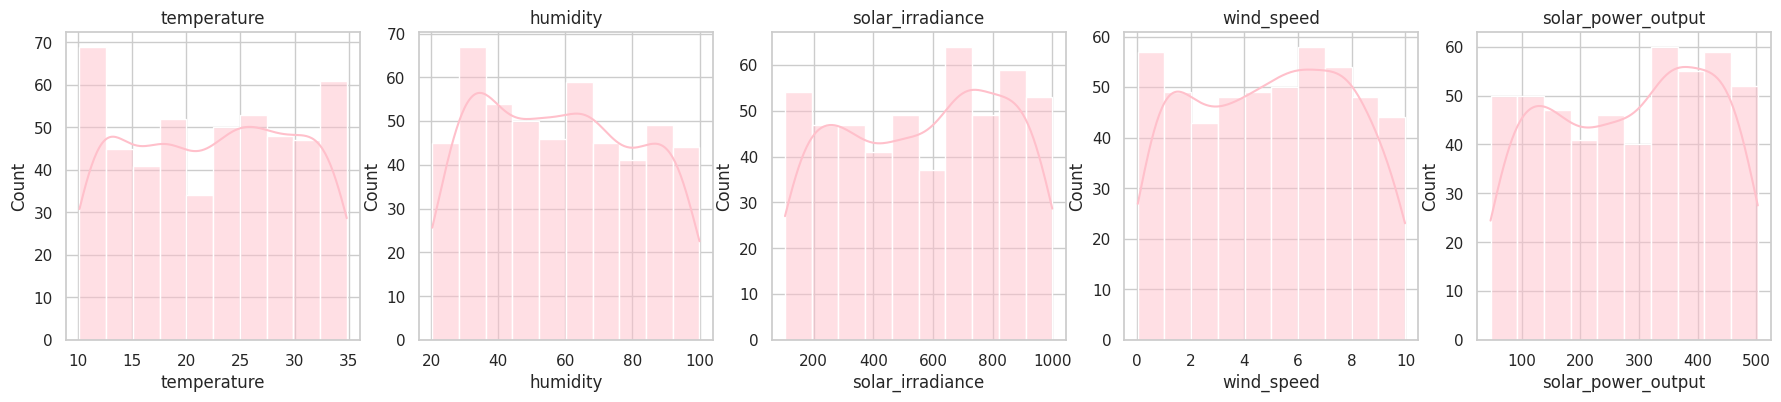

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(22,4))
for ax, col in zip(axes, df.columns):
  sns.histplot(df[col], kde=True, ax=ax, color="pink")
  ax.set_title(col)
plt.show()

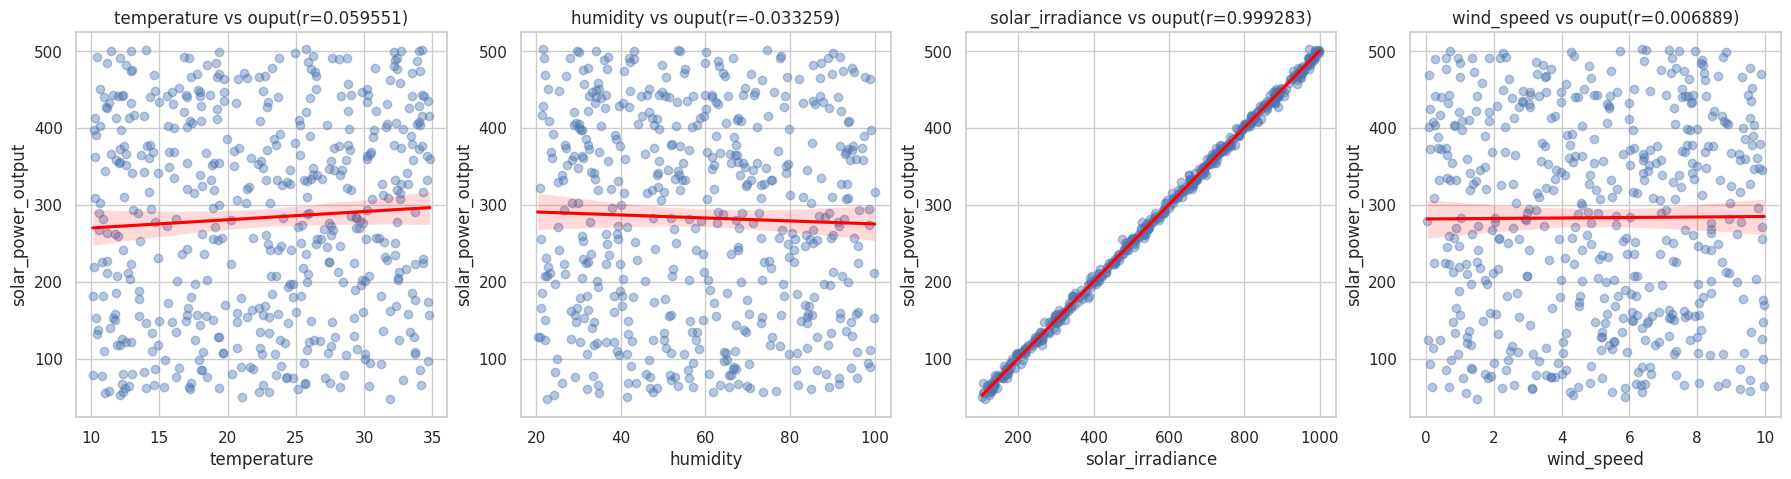

In [ ]:
features =["temperature", "humidity","solar_irradiance","wind_speed"]
fig,axes=plt.subplots(1, 4, figsize=(22,5))
for ax,col in zip(axes, features):
  sns.regplot(x=df[col],y=df["solar_power_output"],ax=ax,scatter_kws={"alpha":0.4},line_kws={"color":"red"})
  r=df[col].corr(df["solar_power_output"])
  ax.set_title(f"{col} vs ouput(r={r:3f})")
plt.show()

multivariant analysis

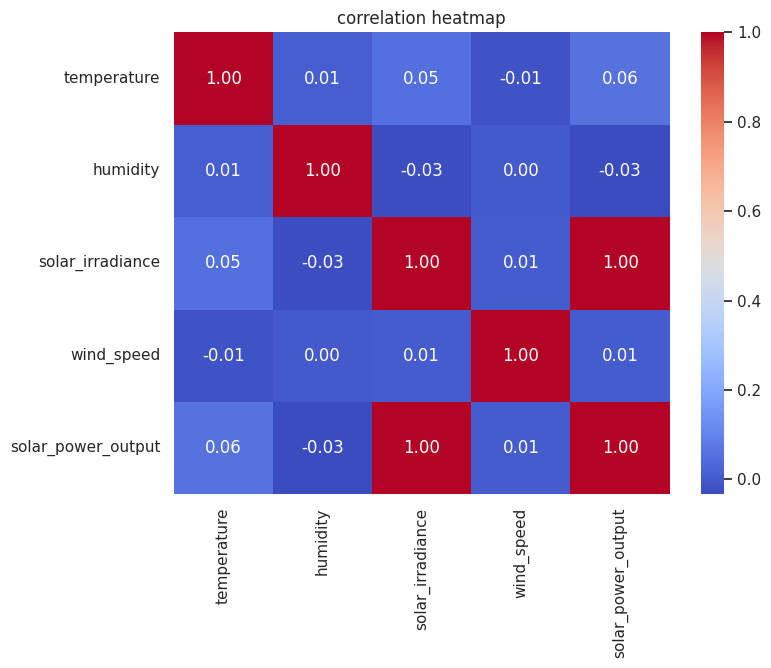

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, fmt=".2f",cmap="coolwarm")
plt.title("correlation heatmap")
plt.show()


data preprocessing

In [ ]:
df.isnull().sum()

,0
temperature,0
humidity,0
solar_irradiance,0
wind_speed,0
solar_power_output,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
X = df[["solar_irradiance"]]
Y = df["solar_power_output"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [ ]:
model = LinearRegression()
# Reshaping X_train to 2D in case the previous cell was not re-run
X_train_2d = X_train.values.reshape(-1, 1) if X_train.ndim == 1 else X_train
model.fit(X_train_2d, Y_train)
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 0.5005361509105947
Intercept: 0.010596779899117337


In [ ]:
Y_pred=model.predict(X_test.values.reshape(-1, 1))
print("R2 :",r2_score(Y_test,Y_pred))
print("MAE :",mean_absolute_error(Y_test,Y_pred))
print("MSE :",mean_squared_error(Y_test,Y_pred))

R2 : 0.9981624336591154
MAE : 4.272564492749517
MSE : 32.333191904121584


graph of linear regression line

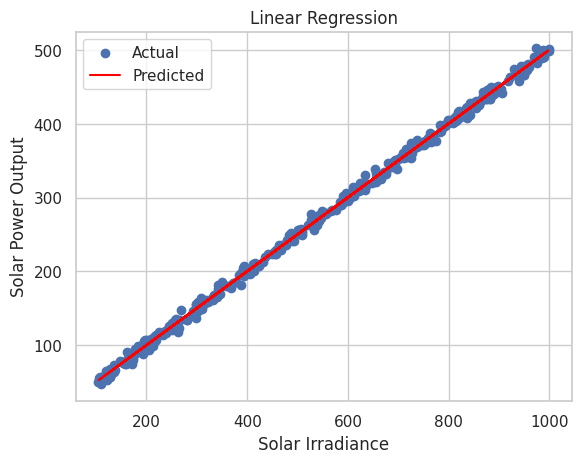

In [ ]:
plt.scatter(X_train, Y_train, label='Actual')
plt.plot(X_test, Y_pred, color='red', label='Predicted')
plt.xlabel('Solar Irradiance')
plt.ylabel('Solar Power Output')
plt.title('Linear Regression')
plt.legend()
plt.show()

In [ ]:
joblib.dump(model, "model.pkl")
print("model saved")

model saved
